In [29]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from implementation import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [33]:
seed = 42

#load data (with header or not)
data, header = load_data('data/x_train.csv', header=True)
y, _ = load_data('data/y_train.csv')

#split data in train and test sets
x_train, x_test, y_train, y_test = split_data(data, y, ratio=0.6, seed=seed)


In [34]:
#see the distribution of the label in the train set
unique_label, count_label = np.unique(y_train, return_counts=True)
print(f"Proportion of 1 value: {count_label[np.where(unique_label == 1)][0] / np.sum(count_label) * 100}%")
print(f"Proportion of -1 value: {count_label[np.where(unique_label == -1)][0] / np.sum(count_label) * 100}%")
print(f"There is approximately {int(count_label[np.where(unique_label == -1)][0] /count_label[np.where(unique_label == 1)][0])} times more -1 value than 1 ")

Proportion of 1 value: 8.755034767194395%
Proportion of -1 value: 91.24496523280561%
There is approximately 10 times more -1 value than 1 


In [ ]:
#search column with more than 50% nan value
_, _, ind_nan = remove_col_full_nan(x_train, header, threshold = 0.5)

#create indicator column for column that have more than 50% of nan value
M = np.isnan(x_train[:, np.ravel(ind_nan)]).astype(float)
M, idx = np.unique(M, axis=1, return_index=True) # keep only one column of distinct motif (avoid colinearity)

#remove columns composed almost entirely of nan value
x_1, header_1, nan_rem = remove_col_full_nan(x_train, header, threshold=0.95)

#remove almost constant columns
x_2, header_2, ind_const = const_column(x_1, header_1, threshold=0.95)

#add the indicator columns (same for header)
x_with_ind = np.c_[x_2, M]
header_with_ind = np.append(header_2, [f'Ind_{header[i]}' for i in np.ravel(ind_nan)[idx]])

#remove column strongly correlated
x_3, header_3, corr_rem = pairwise_corr(x_with_ind, header_with_ind, threshold=0.95)

#normalized data 
x_norm, mean, std = normalize(x_3)

#replace nan value with 0 (after normalization mean=0)
data_without_nan = replace_nan(x_norm)

#add intercept
x_prepro, header_prepro = add_intercept(data_without_nan, header_3)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [35]:
from implementation import *
### same preprocessing but with one_hot_encoder (order is changed)

#remove columns composed almost entirely of nan value
x_1, header_1, nan_rem = remove_col_full_nan(x_train, header, threshold=0.95)

#remove almost constant columns
x_2, header_2, ind_const = const_column(x_1, header_1, threshold=0.95)

x_one_hot, header_one_hot, cont_index, oh_metadata = one_hot_encoder(x_2, header_2, numb_cat=9, index_for_continous=True)
print(x_one_hot.shape)
#normalized data (only continous features)
x_norm, mean_cont, std_cont = normalize(x_one_hot, cont_index)

#replace nan value with 0 (after normalization mean=0)
data_without_nan = replace_nan(x_norm)

#remove column strongly correlated
x_3, header_3, corr_rem = del_correlate(x_one_hot, header_one_hot, threshold=0.95)

#add intercept
x_prepro, header_prepro = add_intercept(data_without_nan, header_3)

['_STATE']
[0]
['_STATE', 'FMONTH']
[0, 1]
['_STATE', 'FMONTH', 'IDATE']
[0, 1, 2]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH']
[0, 1, 2, 3]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY']
[0, 1, 2, 3, 4]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO']
[0, 1, 2, 3, 4, 6]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU']
[0, 1, 2, 3, 4, 6, 7]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT']
[0, 1, 2, 3, 4, 6, 7, 10]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN', 'NUMWOMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11, 12]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', '

In [36]:
x_prepro.shape

(196881, 653)

In [38]:
print(x_prepro)

[[ 1.          0.0648181   0.47181902 ...  0.          1.
   0.        ]
 [ 1.         -0.12220582  0.7584508  ...  1.          0.
   0.        ]
 [ 1.         -0.62093626  1.33171436 ...  0.          1.
   0.        ]
 ...
 [ 1.          1.49866811  0.7584508  ...  0.          0.
   1.        ]
 [ 1.          0.93759637 -0.38807632 ...  1.          0.
   0.        ]
 [ 1.         -1.80542105  1.04508258 ...  0.          1.
   0.        ]]


In [20]:
#report the preprocessing on the test set

#create indicator columns and keep the same as for the train set
M_test = np.isnan(x_test[:, np.ravel(ind_nan)]).astype(float)[:, idx]

#remove nan, constant, correlate columns (same as train set)
test_1 = np.delete(x_test, nan_rem, axis = 1)
test_2 = np.delete(test_1, ind_const, axis = 1)
x_test_ind = np.c_[test_2, M_test] #add indicator functions
test_3 = np.delete(x_test_ind, corr_rem, axis= 1)

#normalize with mean and std of the train set and replace nan value by 0
norm_test = (test_3 - mean) / std
test_4 = replace_nan(norm_test)

#add intercept
test_prepro, _ = add_intercept(test_4)

In [ ]:
#plot the different features of the data
#plot_features(x_norm, header_3)

In [ ]:
from implementation import *
#mean squared error, gradient descent
col = data_without_nan.shape[1]
obs = data_without_nan.shape[0]
w_gd, loss_gd = mean_squared_error_gd(y_train.squeeze(), data_without_nan, np.zeros(col), 40, 0.15)

#mean squared error, stochastic gradient descent
w_sgd, loss_sgd = mean_squared_error_sgd(y_train.squeeze(), data_without_nan, np.zeros(col), 40, 0.15)

#least squared (find best lambda)
w_ls, loss_ls = least_squares(y_train, data_without_nan)

#ridge regression
lambdas = np.logspace(-4, 0, 30)
best_loss, best_lambda = cross_validation(y_train, data_without_nan, 7, lambdas)
w_ridge, loss_ridge = ridge_regression(y_train, data_without_nan, best_lambda)

loss_gd, loss_sgd, loss_ls, loss_ridge

In [ ]:
w_log, log_loss = sgd_logistic_loss_pen(y_train, data_without_nan, np.zeros(data_without_nan.shape[1]), 30, 0.1, 0.05)
log_loss

In [ ]:
#prediction

#mse, gd
pred_gd = test_4.dot(w_gd)
print(pred_gd.shape)
#mse, sgd
pred_sgd = test_4.dot(w_sgd)
print(pred_sgd.shape)
#ls
pred_ls = test_4.dot(w_ls).squeeze()
print(pred_ls.shape)
#ridge
pred_ridge = test_4.dot(w_ridge).squeeze()
print(pred_ridge.shape)
#logistic 
pred_log = test_4.dot(w_log).squeeze()
print(pred_log.shape)

In [ ]:
from implementation import *
#Calculate the accuracy of prediction
nbre_obs = len(y_test)
#gd
bin_gd = threshold_prediction(pred_gd)
acc_gd = accuracy(y_test, bin_gd)
print(acc_gd)
#sgd
bin_sgd = threshold_prediction(pred_sgd)
acc_sgd = accuracy(y_test, bin_sgd)
print(acc_sgd)
#ls
bin_ls = threshold_prediction(pred_ls)
acc_ls = accuracy(y_test, bin_ls)
print(acc_ls)
#ridge
bin_ridge = threshold_prediction(pred_ridge)
acc_ridge = accuracy(y_test, bin_ridge)
print(acc_ridge)
#logistic
bin_log = threshold_prediction(pred_log)
acc_log = accuracy(y_test, bin_log)
print(acc_log)

In [ ]:
from implementation import*
lambdas = np.logspace(-5, 0, 4)
gammas = np.logspace(-5, 0, 4)
lambda_, gamma, log_loss = cross_validation_log(y_train, data_without_nan,5 , lambdas, gammas)

w, loss = sgd_logistic_loss_pen(y_train, data_without_nan, np.zeros(data_without_nan.shape[1]), 10, lambda_, gamma)
pred = test_4.dot(w).squeeze()
bin_ = threshold_prediction(pred)
acc = accuracy(y_test, bin_)
print(acc)
print(lambda_, gamma)

c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:488: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-t))


KeyboardInterrupt: 

In [39]:
from implementation import *
loss_best = np.inf
w = np.zeros(data_without_nan.shape[1])
for _,lambda_ in enumerate(np.logspace(-6, 0, 8)) :
    w_log, loss = newton_log_pen(y_train, data_without_nan, w, 30, lambda_)
    print(lambda_, np.linalg.norm(w_log))
    print(loss)
    if loss < loss_best :
        lost_best = loss
        w = w_log
pred = test_4.dot(w_log).squeeze()
bin_ = threshold_prediction(pred)
acc = accuracy(y_test, bin_)
print(acc)

c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:488: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-t))


1e-06 65.3698856652581
0.22224234988961128
7.196856730011514e-06 55.97568473029078
0.22635487459548492
5.1794746792312125e-05 37.034270771878084
0.2657855527719492
0.0003727593720314938 15.656207731137247
0.42216983711834494
0.0026826957952797246 3.4044329259919555
0.6042790474349217
0.019306977288832496 0.5672131582061929
0.6592832857167232
0.1389495494373136 0.17854601122597016
0.6699468315489854
1.0 0.07092464878551667
0.6792942878369083
0.5301607513819705


c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:488: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-t))


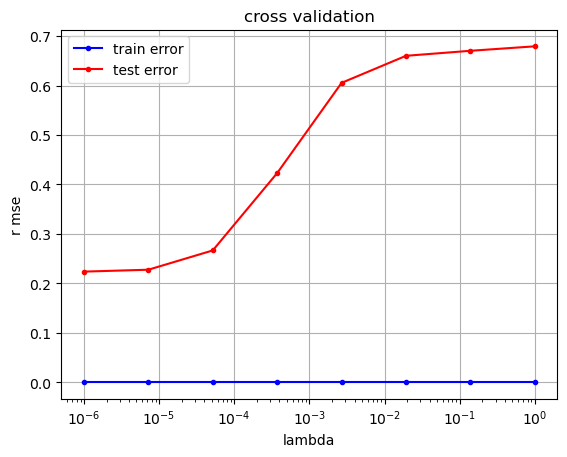

In [41]:
from implementation import *
best_lambda, best_loss = cross_val_new(y_train, data_without_nan, 5, np.logspace(-6, 0, 8))

In [46]:
w_log, loss = newton_log_pen(y_train, data_without_nan, np.zeros(data_without_nan.shape[1]), 30, best_lambda)
y, pred = y_test.squeeze(), test_4.dot(w_log).squeeze()
acc_tot = []
f1_tot = []
for seuil in np.arange(-3, 1, 0.1) : 
    bin_ = threshold_prediction(pred, seuil)
    acc = accuracy(y, bin_)
    tp = np.sum((bin_ == 1) & (y == 1))
    fp = np.sum((bin_ == 1) & (y == -1))
    fn = np.sum((bin_ == -1) & (y == 1))
    f1 = 2 * tp / (2 * tp + fp + fn)
    print(acc)
    print(f1)
    acc_tot.append(acc)
    f1_tot.append(f1)

c:\Users\yvanb\OneDrive\Documenti\epfl\doc\ma1\machine_learning\miniproject_github\CS-433_ML_project_1\implementation.py:488: RuntimeWarning: overflow encountered in exp
  return 1/(1 + np.exp(-t))


0.6186325750072379
0.3006008103954171
0.6375805689731361
0.3086202636512943
0.6569552166029226
0.3179738859099034
0.6750956161336036
0.3260797420945337
0.693281728556844
0.334314438785634
0.7121611531839029
0.3447570155052204
0.7299282307586816
0.35419930770632174
0.7465143919423408
0.36280762233074787
0.7623843844759017
0.37090527674681295
0.778102000700931
0.37985734057276693
0.7928825026284914
0.38768385251255716
0.8067792219665686
0.3947110909568248
0.8206149907812333
0.4027598102630444
0.833064135188261
0.4087536091097979
0.8448123485760434
0.41372362778113575
0.8556463041126365
0.4177499154912265
0.8650174470873269
0.4189814055684911
0.873489569841681
0.4194664895290704
0.8809712465905801
0.41572235311716965
0.8874167644414647
0.4088963558542342
0.8929480244411598
0.4002731657347731
0.8976793088210645
0.3878202206217522
0.9021820287381718
0.3747138752252472
0.9059381047434745
0.3596473029045643
0.9086199277736298
0.33902788493331865
0.9106084385999664
0.31701496012573493
0.912185

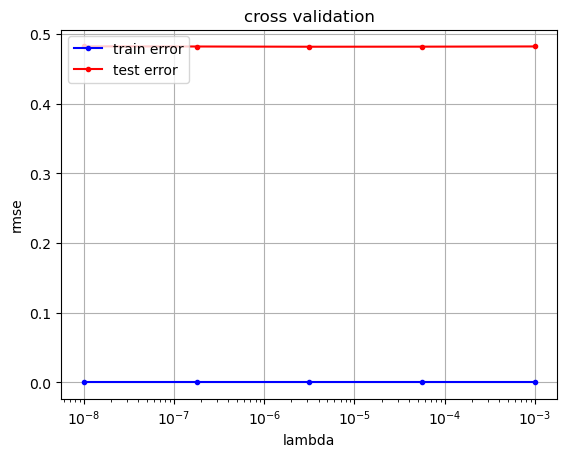

In [ ]:
from implementation import *
#try to calculate the prediction with weighted vector
best_lambda, best_loss = cross_val_new(y_train, data_without_nan, 5, np.logspace(-8, -3, 10), weighted=True)


In [ ]:
weight = ponderate_vector(y_train)
w_log, loss = newton_log_pen(y_train, x_prepro, np.zeros(x_prepro.shape[1]), 30, best_lambda, weighted=weight)
y, pred = y_test.squeeze(), test_4.dot(w_log).squeeze()
acc_tot = []
f1_tot = []
for seuil in np.arange(-3, 1, 0.1) : 
    bin_ = threshold_prediction(pred, seuil)
    acc = accuracy(y, bin_)
    tp = np.sum((bin_ == 1) & (y == 1))
    fp = np.sum((bin_ == 1) & (y == -1))
    fn = np.sum((bin_ == -1) & (y == 1))
    f1 = 2 * tp / (2 * tp + fp + fn)
    print(acc)
    print(f1)
    acc_tot.append(acc)
    f1_tot.append(f1)

0.22519694637877702
0.18678330961024836
0.24098313194264556
0.18985118321541838
0.2569369314458988
0.19303326162502069
0.27336309750559984
0.19639035405537486
0.29088637298672804
0.20016155921832837
0.30792204428055525
0.20392961054439654
0.3257653100095997
0.20790519494468512
0.343989516509973
0.21216557479046957
0.36191658920870984
0.21651153000608073
0.3804988800341323
0.22128368672068036
0.39870023008822586
0.22605540573670016
0.4168253919880537
0.23105360443622922
0.4353010193975041
0.23616220951203173
0.4540052112697518
0.241795213610106
0.47165038779770524
0.24701947925036374
0.49033934203909973
0.25316229583235644
0.508853063525683
0.259320962831045
0.5273744038276929
0.2656264797802822
0.5457662242674509
0.27216348853675804
0.5635942523656422
0.2787347637755616
0.5817498895271763
0.28578119511338357
0.5999817148429762
0.2930658408509492
0.6173069011230133
0.2999888511065277
0.6355920581467993
0.30833526145303103
0.6527877245645847
0.315936416445265
0.6696481631036006
0.3237257

(0.8999999999999995, 0.4147719039361982)

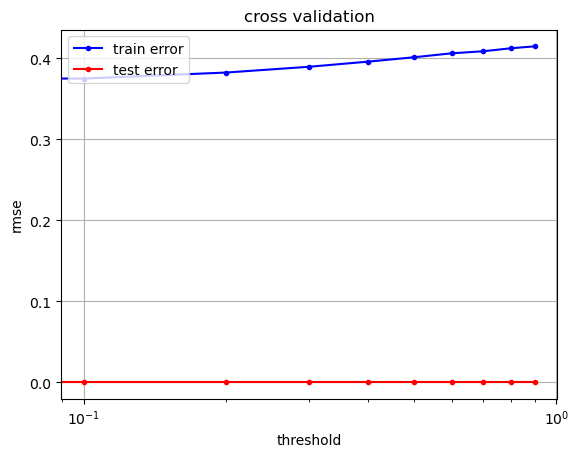

In [39]:
#cross validation with best lambda to find best threshold
best_thresh, best_loss = cross_validation_threshold(y_train, x_prepro, 5, best_lambda, np.arange(-1, 1, 0.1), max_iters=10, weighted=True)
best_thresh, best_loss

In [25]:
#tester sur le test set
weight = ponderate_vector(y_train)
w, _ = newton_log_pen(y_train, x_prepro, np.zeros(x_prepro.shape[1]), 15, best_lambda, weighted=weight)
y_pred = threshold_prediction(test_prepro @ w, best_thresh)
accuracy = accuracy(y_test, y_pred)
f1_score = f1_score(y_test, y_pred)
print(accuracy, f1_score)

0.7873310494650784 0.4170245252409581


In [26]:
#complet preprocess for all the data to make a prediction of the test set for competition
#load the train
data, header = load_data('data/x_train.csv', header=True)
y, _ = load_data('data/y_train.csv')

#preprocess
_, _, ind_nan = remove_col_full_nan(data, header, threshold = 0.5)

M = np.isnan(data[:, np.ravel(ind_nan)]).astype(float)
M, idx = np.unique(M, axis=1, return_index=True) 

x_1, header_1, nan_rem = remove_col_full_nan(data, header, threshold=0.95)

x_2, header_2, ind_const = const_column(x_1, header_1, threshold=0.95)

x_with_ind = np.c_[x_2, M]
header_with_ind = np.append(header_2, [f'Ind_{header[i]}' for i in np.ravel(ind_nan)[idx]])

x_3, header_3, corr_rem = pairwise_corr(x_with_ind, header_with_ind, threshold=0.95)

x_norm, mean, std = normalize(x_3)

data_without_nan = replace_nan(x_norm)

train_prepro, header_prepro = add_intercept(data_without_nan, header_3)

c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\yvanb\miniforge3\envs\MLCourse\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


In [27]:
#make the same for the test set
#load data
test,_ = load_data('data/x_test.csv', header=True)

#preprocess
M_test = np.isnan(test[:, np.ravel(ind_nan)]).astype(float)[:, idx]

#remove nan, constant, correlate columns (same as train set)
test_1 = np.delete(test, nan_rem, axis = 1)
test_2 = np.delete(test_1, ind_const, axis = 1)
x_test_ind = np.c_[test_2, M_test] #add indicator functions
test_3 = np.delete(x_test_ind, corr_rem, axis= 1)

#normalize with mean and std of the train set and replace nan value by 0
norm_test = (test_3 - mean) / std
test_4 = replace_nan(norm_test)

#add intercept
test_prepro, _ = add_intercept(test_4)

In [28]:
#train the model
weight = ponderate_vector(y)
w, _ = newton_log_pen(y, train_prepro, np.zeros(train_prepro.shape[1]), 15, best_lambda, weighted=weight)

In [29]:
#make prediction
y_pred = threshold_prediction(test_prepro @ w, best_thresh)

In [30]:
from implementation import *
#create submission
ids = get_ind_for_sub('data/x_test.csv')
create_csv_submission(ids, y_pred, "first_submission_newton.csv")

***Trying new submission with one hot encoder***

In [49]:
from implementation import *

seed = 42

#load data (with header or not)
data, header = load_data('data/x_train.csv', header=True)
y, _ = load_data('data/y_train.csv')

#split data in train and test sets
x_train, x_test, y_train, y_test = split_data(data, y, ratio=0.6, seed=seed)

In [50]:
#remove columns composed almost entirely of nan value
x_1, header_1, nan_rem = remove_col_full_nan(x_train, header, threshold=0.95)

#remove almost constant columns
x_2, header_2, ind_const = const_column(x_1, header_1, threshold=0.95)

x_one_hot, header_one_hot, cont_index, oh_metadata = one_hot_encoder(x_2, header_2, numb_cat=9, index_for_continous=True)

#normalized data (only continous features)
x_norm, mean_cont, std_cont = normalize(x_one_hot, cont_index)

#replace nan value with 0 (after normalization mean=0)
data_without_nan = replace_nan(x_norm)

#remove column strongly correlated
x_3, header_3, corr_rem = del_correlate(data_without_nan, header_one_hot, threshold=0.95)

#add intercept
x_prepro, header_prepro = add_intercept(x_3, header_3)

['_STATE']
[0]
['_STATE', 'FMONTH']
[0, 1]
['_STATE', 'FMONTH', 'IDATE']
[0, 1, 2]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH']
[0, 1, 2, 3]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY']
[0, 1, 2, 3, 4]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO']
[0, 1, 2, 3, 4, 6]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU']
[0, 1, 2, 3, 4, 6, 7]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT']
[0, 1, 2, 3, 4, 6, 7, 10]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN', 'NUMWOMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11, 12]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', '

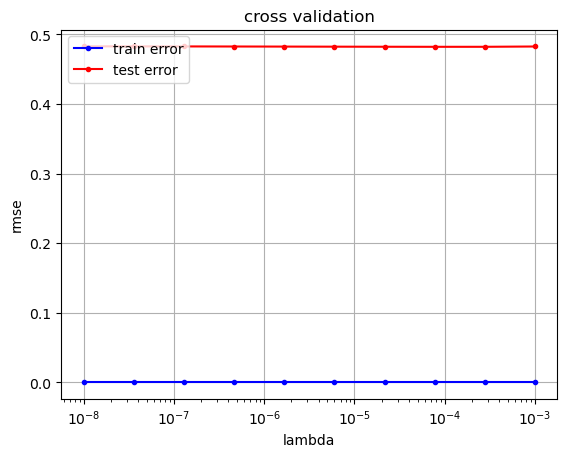

In [51]:
#try to calculate the prediction with weighted vector
best_lambda, best_loss = cross_val_new(y_train, x_prepro, 5, np.logspace(-8, -3, 10), weighted=True)

(1.0000000000000027, 0.4143500135106996)

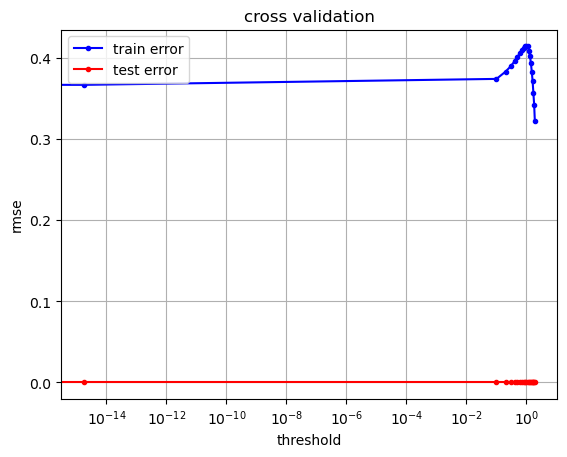

In [52]:
#cross validation with best lambda to find best threshold
best_thresh, best_loss = cross_validation_threshold(y_train, x_prepro, 5, best_lambda, np.arange(-2, 2, 0.1), max_iters=10, weighted=True)
best_thresh, best_loss

In [54]:
#process the test set

#remove nan, constant, correlate columns (same as train set)
test_1 = np.delete(x_test, nan_rem, axis = 1)
test_2 = np.delete(test_1, ind_const, axis = 1)


test_3 = one_hot_for_test(test_2, oh_metadata)
print(test_3.shape)
#normalize with mean and std of the train set and replace nan value by 0
test_3[:,cont_index] = (test_3[:,cont_index] - mean_cont) / std_cont
test_4 = replace_nan(test_3)
test_5 = np.delete(test_4, corr_rem, axis=1)
#add intercept
test_prepro, _ = add_intercept(test_5)
print(test_prepro.shape)

(131254, 652)
(131254, 510)


In [55]:
weight = ponderate_vector(y_train)
w, _ = newton_log_pen(y_train, x_prepro, np.zeros(x_prepro.shape[1]), 15, best_lambda, weighted=weight)
y_pred = threshold_prediction(test_prepro @ w, best_thresh)
accuracy = accuracy(y_test, y_pred)
f1_score = f1_score(y_test, y_pred)
print(accuracy, f1_score)

0.7965963622210831 0.4230204299639471


In [56]:
#complet preprocess for all the data to make a prediction of the test set for competition
#load the train
data, header = load_data('data/x_train.csv', header=True)
y, _ = load_data('data/y_train.csv')

#remove columns composed almost entirely of nan value
train_1, header_1, nan_rem = remove_col_full_nan(data, header, threshold=0.95)

#remove almost constant columns
train_2, header_2, ind_const = const_column(train_1, header_1, threshold=0.95)

train_one_hot, header_one_hot, cont_index, oh_metadata = one_hot_encoder(train_2, header_2, numb_cat=9, index_for_continous=True)

#normalized data (only continous features)
train_norm, mean_cont, std_cont = normalize(train_one_hot, cont_index)

#replace nan value with 0 (after normalization mean=0)
train_without_nan = replace_nan(train_norm)

#remove column strongly correlated
train_3, header_3, corr_rem = del_correlate(train_without_nan, header_one_hot, threshold=0.95)

#add intercept
train_prepro_full, header_prepro_full = add_intercept(train_3, header_3)

['_STATE']
[0]
['_STATE', 'FMONTH']
[0, 1]
['_STATE', 'FMONTH', 'IDATE']
[0, 1, 2]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH']
[0, 1, 2, 3]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY']
[0, 1, 2, 3, 4]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO']
[0, 1, 2, 3, 4, 6]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU']
[0, 1, 2, 3, 4, 6, 7]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT']
[0, 1, 2, 3, 4, 6, 7, 10]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', 'CELLFON3_nan', 'NUMADULT', 'NUMMEN', 'NUMWOMEN']
[0, 1, 2, 3, 4, 6, 7, 10, 11, 12]
['_STATE', 'FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE_cat0', 'SEQNO', '_PSU', 'CELLFON3_cat0', '

In [59]:
#make the same for the test set
#load data
test,_ = load_data('data/x_test.csv', header=True)

test_1 = np.delete(test, nan_rem, axis = 1)
test_2 = np.delete(test_1, ind_const, axis = 1)


test_3 = one_hot_for_test(test_2, oh_metadata)

#normalize with mean and std of the train set and replace nan value by 0
test_3[:,cont_index] = (test_3[:,cont_index] - mean_cont) / std_cont
test_4 = replace_nan(test_3)
test_5 = np.delete(test_4, corr_rem, axis=1)

#add intercept
test_prepro_full, _ = add_intercept(test_5)

In [60]:
#train the model
weight = ponderate_vector(y)
w, _ = newton_log_pen(y, train_prepro_full, np.zeros(train_prepro_full.shape[1]), 15, best_lambda, weighted=weight)

In [61]:
#make prediction
y_pred = threshold_prediction(test_prepro_full @ w, best_thresh)

In [62]:
#create submission
ids = get_ind_for_sub('data/x_test.csv')
create_csv_submission(ids, y_pred, "submission_oh_newton.csv")